Little (60745, 3)
Middle (60745, 3)
Ring (60745, 3)
Index (60745, 3)
Thumb (60745, 3)
Little batches: 6074
Middle batches: 6074
Ring batches: 6074
Index batches: 6074
Thumb batches: 6074


10-MINUTE DATASET
Features: (30370, 40)
Labels: (30370,)
Features per batch: 40

Class Distribution
Little    6074
Middle    6074
Ring      6074
Index     6074
Thumb     6074
Name: count, dtype: int64

Training: (21259, 40)
Testing: (9111, 40)


RANDOM TEST BATCH
Finger: Little
Test index: 2562

Reading | EMG1 | EMG2
      1 |    23.00 |    12.00
      2 |    53.00 |     0.00
      3 |   134.00 |   126.00
      4 |     0.00 |     1.00
      5 |     0.00 |    35.00
      6 |    30.00 |    24.00
      7 |     0.00 |     0.00
      8 |    23.00 |     0.00
      9 |     0.00 |     0.00
     10 |     0.00 |    27.00

Statistical Features
Statistic                          EMG1           EMG2
Mean                            26.3000        22.5000
Median                          11.5000         6.5000
Minim

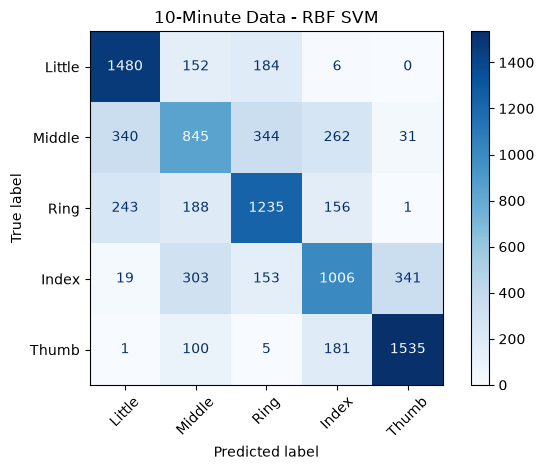

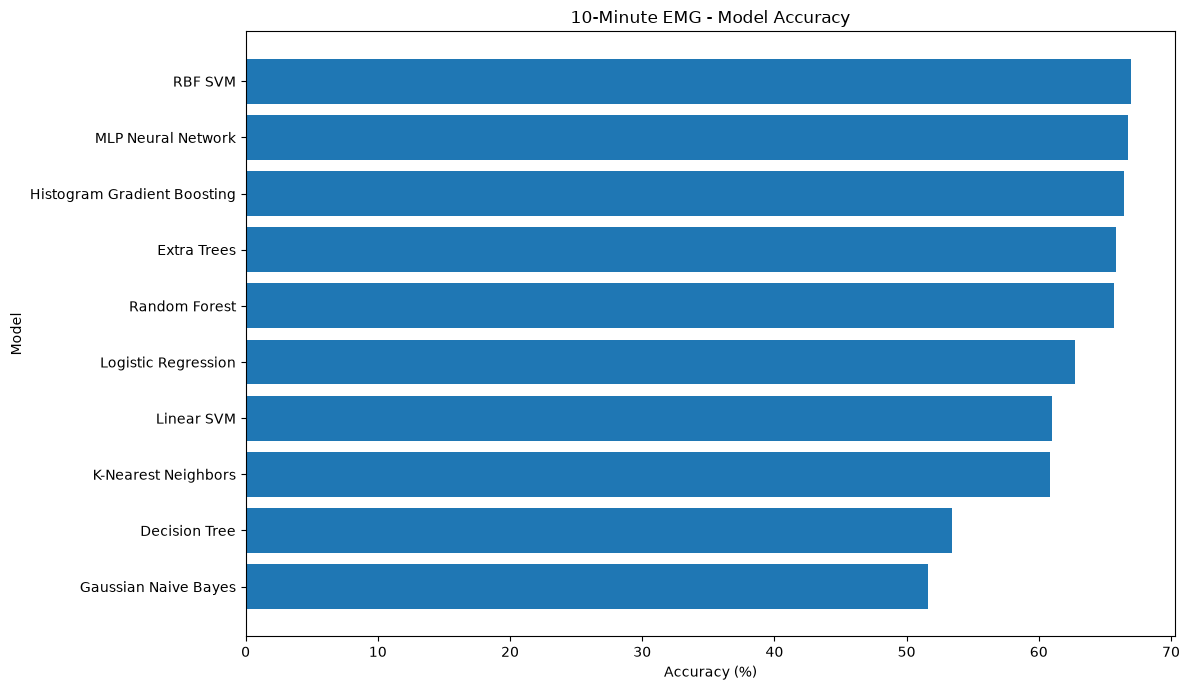

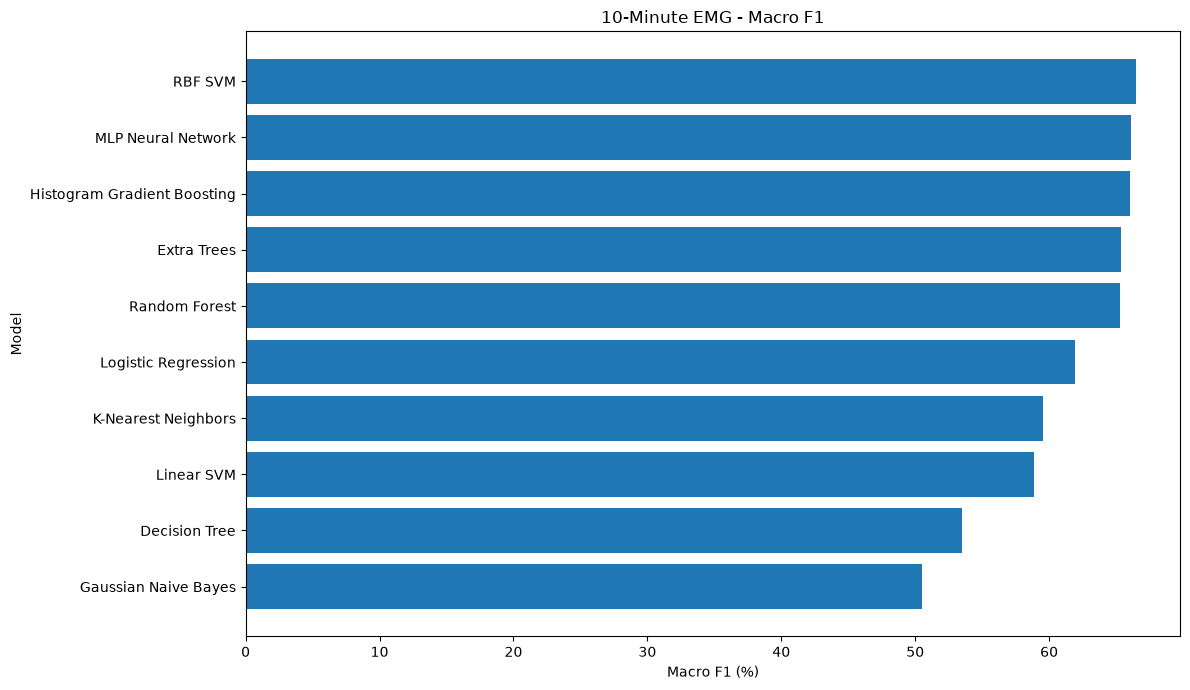



RANDOM BATCH PREDICTIONS
Actual: Little
                      Model Prediction  Correct
        Logistic Regression     Little     True
        K-Nearest Neighbors     Middle    False
                    RBF SVM     Little     True
                 Linear SVM     Little     True
              Decision Tree     Middle    False
              Random Forest     Little     True
                Extra Trees     Little     True
Histogram Gradient Boosting     Little     True
       Gaussian Naive Bayes     Middle    False
         MLP Neural Network     Little     True


RANDOM FOREST TOP 20 FEATURES
                 Feature  Importance
             EMG1_Median    0.083228
               EMG1_Mean    0.076107
EMG1_Mean_Absolute_Value    0.075175
                EMG1_RMS    0.051064
 EMG1_Standard_Deviation    0.042232
           EMG1_Variance    0.041473
    EMG1_Waveform_Length    0.036978
            EMG1_Maximum    0.035617
              EMG1_Range    0.034034
              Raw_EMG1_4    

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings(
    "ignore",
    category=ConvergenceWarning
)


# ============================================================
# LOAD 10-MINUTE DATA
# ============================================================

little_10min = pd.read_csv(
    "../EMG Recordings/little_finger 10mins.csv"
)

middle_10min = pd.read_csv(
    "../EMG Recordings/middle_finger_10mins.csv"
)

ring_10min = pd.read_csv(
    "../EMG Recordings/ring_finger_10mins.csv"
)

index_10min = pd.read_csv(
    "../EMG Recordings/index_finger_10mins.csv"
)

thumb_10min = pd.read_csv(
    "../EMG Recordings/thumb_finger_10mins.csv"
)


recordings = {
    "Little": little_10min.head(60745),
    "Middle": middle_10min.head(60745),
    "Ring": ring_10min.head(60745),
    "Index": index_10min.head(60745),
    "Thumb": thumb_10min.head(60745)
}


for finger, data in recordings.items():

    print(
        finger,
        data.shape
    )


# ============================================================
# STATISTICAL FEATURES
# ============================================================

def calculate_statistics(values):

    values = values.astype(float)

    mean_value = np.mean(values)
    median_value = np.median(values)
    minimum_value = np.min(values)
    maximum_value = np.max(values)
    standard_deviation = np.std(values)
    variance_value = np.var(values)
    value_range = maximum_value - minimum_value
    rms_value = np.sqrt(np.mean(values ** 2))
    mean_absolute_value = np.mean(np.abs(values))
    waveform_length = np.sum(np.abs(np.diff(values)))

    return [
        mean_value,
        median_value,
        minimum_value,
        maximum_value,
        standard_deviation,
        variance_value,
        value_range,
        rms_value,
        mean_absolute_value,
        waveform_length
    ]


# ============================================================
# CREATE BATCHES
# ============================================================

def create_batches(data, batch_size=10):

    signals = data[
        ["emg1", "emg2"]
    ].values

    batches = []

    for i in range(
        0,
        len(signals),
        batch_size
    ):

        batch = signals[
            i:i + batch_size
        ]

        if len(batch) != batch_size:
            continue

        raw_features = batch.flatten()

        emg1_statistics = calculate_statistics(
            batch[:, 0]
        )

        emg2_statistics = calculate_statistics(
            batch[:, 1]
        )

        combined_features = np.concatenate(
            [
                raw_features,
                emg1_statistics,
                emg2_statistics
            ]
        )

        batches.append(
            combined_features
        )

    return np.array(
        batches
    )


# ============================================================
# FEATURE NAMES
# ============================================================

statistic_names = [
    "Mean",
    "Median",
    "Minimum",
    "Maximum",
    "Standard_Deviation",
    "Variance",
    "Range",
    "RMS",
    "Mean_Absolute_Value",
    "Waveform_Length"
]


feature_names = []


for reading in range(1, 11):

    feature_names.append(
        f"Raw_EMG1_{reading}"
    )

    feature_names.append(
        f"Raw_EMG2_{reading}"
    )


for statistic in statistic_names:

    feature_names.append(
        f"EMG1_{statistic}"
    )


for statistic in statistic_names:

    feature_names.append(
        f"EMG2_{statistic}"
    )


# ============================================================
# PREPARE DATASET
# ============================================================

emg_features = []

finger_labels = []


for finger, data in recordings.items():

    batches = create_batches(
        data
    )

    print(
        finger,
        "batches:",
        len(batches)
    )

    for batch in batches:

        emg_features.append(
            batch
        )

        finger_labels.append(
            finger
        )


emg_features = np.array(
    emg_features
)

finger_labels = np.array(
    finger_labels
)


print("\n")
print("=" * 70)
print("10-MINUTE DATASET")
print("=" * 70)


print(
    "Features:",
    emg_features.shape
)


print(
    "Labels:",
    finger_labels.shape
)


print(
    "Features per batch:",
    emg_features.shape[1]
)


print("\nClass Distribution")


print(
    pd.Series(
        finger_labels
    ).value_counts()
)


# ============================================================
# 60/40 RANDOM SPLIT
# ============================================================

(
    train_features,
    test_features,
    train_labels,
    test_labels

) = train_test_split(

    emg_features,
    finger_labels,

    train_size=0.70,
    test_size=0.30,

    random_state=42,

    shuffle=True,

    stratify=finger_labels
)


print("\nTraining:", train_features.shape)

print(
    "Testing:",
    test_features.shape
)


# ============================================================
# STANDARD SCALING
# ============================================================

scaler = StandardScaler()


train_features_scaled = scaler.fit_transform(
    train_features
)


test_features_scaled = scaler.transform(
    test_features
)


# ============================================================
# RANDOM TEST BATCH
# ============================================================

random_index = np.random.randint(
    0,
    len(test_features)
)


random_raw_features = test_features[
    random_index
]


random_scaled_features = test_features_scaled[
    random_index
]


random_label = test_labels[
    random_index
]


raw_signal = random_raw_features[
    :20
].reshape(
    10,
    2
)


print("\n")
print("=" * 70)
print("RANDOM TEST BATCH")
print("=" * 70)


print(
    "Finger:",
    random_label
)


print(
    "Test index:",
    random_index
)


print("\nReading | EMG1 | EMG2")


for i in range(10):

    print(
        f"{i + 1:>7} | "
        f"{raw_signal[i, 0]:>8.2f} | "
        f"{raw_signal[i, 1]:>8.2f}"
    )


# ============================================================
# STATISTICS FOR RANDOM BATCH
# ============================================================

emg1_stats = random_raw_features[
    20:30
]


emg2_stats = random_raw_features[
    30:40
]


print("\nStatistical Features")


print(
    f"{'Statistic':<24}"
    f"{'EMG1':>15}"
    f"{'EMG2':>15}"
)


for i in range(
    len(statistic_names)
):

    print(
        f"{statistic_names[i]:<24}"
        f"{emg1_stats[i]:>15.4f}"
        f"{emg2_stats[i]:>15.4f}"
    )


# ============================================================
# MODELS
# ============================================================

models = {

    "Logistic Regression":
        LogisticRegression(
            max_iter=3000,
            C=1.0,
            random_state=42
        ),

    "K-Nearest Neighbors":
        KNeighborsClassifier(
            n_neighbors=7,
            weights="distance",
            n_jobs=-1
        ),

    "RBF SVM":
        SVC(
            kernel="rbf",
            C=3.0,
            gamma="scale"
        ),

    "Linear SVM":
        LinearSVC(
            C=1.0,
            max_iter=5000,
            random_state=42
        ),

    "Decision Tree":
        DecisionTreeClassifier(
            random_state=42,
            min_samples_leaf=2
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ),

    "Extra Trees":
        ExtraTreesClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ),

    "Histogram Gradient Boosting":
        HistGradientBoostingClassifier(
            max_iter=300,
            learning_rate=0.08,
            max_leaf_nodes=31,
            random_state=42
        ),

    "Gaussian Naive Bayes":
        GaussianNB(),

    "MLP Neural Network":
        MLPClassifier(
            hidden_layer_sizes=(
                128,
                64
            ),
            activation="relu",
            solver="adam",
            learning_rate_init=0.001,
            max_iter=300,
            early_stopping=True,
            validation_fraction=0.10,
            n_iter_no_change=15,
            random_state=42
        )
}


# ============================================================
# TRAIN ALL MODELS
# ============================================================

results = []

trained_models = {}

model_predictions = {}


print("\n")
print("=" * 70)
print("TRAINING 10 MODELS")
print("=" * 70)


for model_number, (
    model_name,
    model
) in enumerate(
    models.items(),
    start=1
):

    print(
        f"\n[{model_number}/10] {model_name}"
    )

    try:

        train_start = time.perf_counter()


        model.fit(
            train_features_scaled,
            train_labels
        )


        train_end = time.perf_counter()


        prediction_start = time.perf_counter()


        predicted_labels = model.predict(
            test_features_scaled
        )


        prediction_end = time.perf_counter()


        accuracy = accuracy_score(
            test_labels,
            predicted_labels
        )


        balanced_accuracy = balanced_accuracy_score(
            test_labels,
            predicted_labels
        )


        precision = precision_score(
            test_labels,
            predicted_labels,
            average="macro",
            zero_division=0
        )


        recall = recall_score(
            test_labels,
            predicted_labels,
            average="macro",
            zero_division=0
        )


        macro_f1 = f1_score(
            test_labels,
            predicted_labels,
            average="macro",
            zero_division=0
        )


        weighted_f1 = f1_score(
            test_labels,
            predicted_labels,
            average="weighted",
            zero_division=0
        )


        training_time = (
            train_end -
            train_start
        )


        prediction_time = (
            prediction_end -
            prediction_start
        )


        results.append(
            {
                "Model":
                    model_name,

                "Accuracy":
                    accuracy,

                "Balanced Accuracy":
                    balanced_accuracy,

                "Macro Precision":
                    precision,

                "Macro Recall":
                    recall,

                "Macro F1":
                    macro_f1,

                "Weighted F1":
                    weighted_f1,

                "Training Time":
                    training_time,

                "Prediction Time":
                    prediction_time
            }
        )


        trained_models[
            model_name
        ] = model


        model_predictions[
            model_name
        ] = predicted_labels


        print(
            f"Accuracy: "
            f"{accuracy * 100:.4f}%"
        )


        print(
            f"Macro F1: "
            f"{macro_f1 * 100:.4f}%"
        )


        print(
            f"Training: "
            f"{training_time:.3f} seconds"
        )


        print(
            f"Prediction: "
            f"{prediction_time:.3f} seconds"
        )


    except Exception as error:

        print(
            "FAILED:",
            error
        )


# ============================================================
# RESULTS
# ============================================================

results = pd.DataFrame(
    results
)


results = results.sort_values(
    by=[
        "Accuracy",
        "Macro F1"
    ],
    ascending=False
).reset_index(
    drop=True
)


results.insert(
    0,
    "Rank",
    np.arange(
        1,
        len(results) + 1
    )
)


display_results = results.copy()


percentage_columns = [
    "Accuracy",
    "Balanced Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1"
]


for column in percentage_columns:

    display_results[column] = (
        display_results[column] * 100
    )


print("\n")
print("=" * 120)
print("10-MINUTE DATA MODEL COMPARISON")
print("=" * 120)


print(
    display_results.to_string(
        index=False,
        float_format=lambda value:
            f"{value:.4f}"
    )
)


results.to_csv(
    "10min_10_model_comparison.csv",
    index=False
)


# ============================================================
# BEST MODEL
# ============================================================

best_model_name = results.iloc[
    0
]["Model"]


best_model = trained_models[
    best_model_name
]


best_predictions = model_predictions[
    best_model_name
]


best_accuracy = results.iloc[
    0
]["Accuracy"]


best_f1 = results.iloc[
    0
]["Macro F1"]


print("\n")
print("=" * 70)
print("BEST MODEL")
print("=" * 70)


print(
    "Model:",
    best_model_name
)


print(
    f"Accuracy: "
    f"{best_accuracy * 100:.4f}%"
)


print(
    f"Macro F1: "
    f"{best_f1 * 100:.4f}%"
)


print("\nClassification Report\n")


print(
    classification_report(
        test_labels,
        best_predictions,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

finger_names = [
    "Little",
    "Middle",
    "Ring",
    "Index",
    "Thumb"
]


matrix = confusion_matrix(
    test_labels,
    best_predictions,
    labels=finger_names
)


display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=finger_names
)


display.plot(
    cmap="Blues"
)


plt.title(
    f"10-Minute Data - {best_model_name}"
)


plt.xticks(
    rotation=45
)


plt.tight_layout()

plt.show()


# ============================================================
# ACCURACY GRAPH
# ============================================================

plot_results = results.sort_values(
    "Accuracy",
    ascending=True
)


plt.figure(
    figsize=(12, 7)
)


plt.barh(
    plot_results["Model"],
    plot_results["Accuracy"] * 100
)


plt.xlabel(
    "Accuracy (%)"
)


plt.ylabel(
    "Model"
)


plt.title(
    "10-Minute EMG - Model Accuracy"
)


plt.tight_layout()

plt.show()


# ============================================================
# F1 GRAPH
# ============================================================

plot_results = results.sort_values(
    "Macro F1",
    ascending=True
)


plt.figure(
    figsize=(12, 7)
)


plt.barh(
    plot_results["Model"],
    plot_results["Macro F1"] * 100
)


plt.xlabel(
    "Macro F1 (%)"
)


plt.ylabel(
    "Model"
)


plt.title(
    "10-Minute EMG - Macro F1"
)


plt.tight_layout()

plt.show()


# ============================================================
# RANDOM BATCH WITH ALL MODELS
# ============================================================

print("\n")
print("=" * 70)
print("RANDOM BATCH PREDICTIONS")
print("=" * 70)


print(
    "Actual:",
    random_label
)


random_prediction_results = []


for model_name, model in trained_models.items():

    prediction = model.predict(
        random_scaled_features.reshape(
            1,
            -1
        )
    )[0]


    random_prediction_results.append(
        {
            "Model":
                model_name,

            "Prediction":
                prediction,

            "Correct":
                prediction == random_label
        }
    )


random_prediction_results = pd.DataFrame(
    random_prediction_results
)


print(
    random_prediction_results.to_string(
        index=False
    )
)


# ============================================================
# RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

random_forest_model = trained_models.get(
    "Random Forest"
)


if random_forest_model is not None:

    feature_importance = pd.DataFrame(
        {
            "Feature":
                feature_names,

            "Importance":
                random_forest_model.feature_importances_
        }
    )


    feature_importance = feature_importance.sort_values(
        "Importance",
        ascending=False
    ).reset_index(
        drop=True
    )


    print("\n")
    print("=" * 70)
    print("RANDOM FOREST TOP 20 FEATURES")
    print("=" * 70)


    print(
        feature_importance.head(
            20
        ).to_string(
            index=False
        )
    )


    feature_importance.to_csv(
        "10min_random_forest_feature_importance.csv",
        index=False
    )


# ============================================================
# SUMMARY
# ============================================================

print("\n")
print("=" * 70)
print("FINAL SUMMARY")
print("=" * 70)


print(
    "Total batches:",
    len(emg_features)
)


print(
    "Training batches:",
    len(train_features)
)


print(
    "Testing batches:",
    len(test_features)
)


print(
    "Features per batch:",
    emg_features.shape[1]
)


print(
    "Best model:",
    best_model_name
)


print(
    f"Best accuracy: "
    f"{best_accuracy * 100:.4f}%"
)


print(
    f"Best Macro F1: "
    f"{best_f1 * 100:.4f}%"
)